# Prediction model of RRFs of compounds detected by GC/MS

## 0. Conception

*Which decision are we going to inform?* \
We will assist labs by predicting RRFs detected by GC/MS

*What is our prediction estimand?* \
Input data :  Several molecular and physico-chemical characteristics.
The outcome is continuous : Relative Response Factor

*How can you measure the model's success?* \
The model's success will be mostly assessed with the one having the highest R², lowest test MSE. \

### Loading Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chemistry
import pubchempy as pcp
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.ML.Descriptors import MoleculeDescriptors

# Scikit-learn
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.tree import plot_tree
from sklearn.model_selection import KFold, cross_val_predict
from lightgbm import LGBMRegressor


sns.set(style="whitegrid")

# Hyperparameter tuning
import optuna

c:\Users\misak\anaconda3\envs\APPY2025\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data acquisition

The excel file was created by manually copying the table from the US FDA CLAP list and the table S1 supplementary data from Yun et al.


In [2]:
df = pd.read_excel('processed_data/RRFML.xlsx')

## 2. Exploratory data analysis

In [3]:
df.describe()


,DBE,MW,BP,logP,Refractive Index,5 µg/mL,10 µg/mL,20 µg/mL
count,92.000000,92.000000,91.000000,92.000000,89.000000,92.000000,92.000000,92.000000
mean,5.309783,303.179348,359.889011,6.055326,1.523247,0.374228,0.406674,0.412489
std,4.100953,160.177748,127.047844,4.117937,0.087404,0.463968,0.484548,0.446450
min,0.000000,102.200000,148.300000,-0.660000,1.289000,0.000000,0.000000,0.000000
25%,2.000000,195.550000,259.400000,3.142500,1.454000,0.030250,0.037250,0.053500
50%,4.000000,285.450000,359.400000,5.355000,1.499000,0.207000,0.287000,0.278000
75%,8.000000,375.600000,435.500000,8.475000,1.585000,0.534000,0.527000,0.608500
max,20.000000,1177.600000,779.000000,23.000000,1.757000,2.551000,2.143000,1.810000


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 92 entries, 0 to 91
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Code               92 non-null     str    
 1   IUPAC name         92 non-null     str    
 2   CAS #              92 non-null     str    
 3   Empirical Formula  92 non-null     str    
 4   DBE                92 non-null     float64
 5   MW                 92 non-null     float64
 6   BP                 91 non-null     float64
 7   pKa                65 non-null     str    
 8   logP               92 non-null     float64
 9   Refractive Index   89 non-null     float64
 10  5 µg/mL            92 non-null     float64
 11  10 µg/mL           92 non-null     float64
 12  20 µg/mL           92 non-null     float64
dtypes: float64(8), str(5)
memory usage: 15.0 KB


## 3. Data preprocessing

We will first convert the CAS number of the extractables into Smiles using pubchem library. This is necessary to get molecular descriptors from the RdKit library.

In [5]:
def get_smiles_from_cas(cas):
    """Utility to fetch SMILES via PubChem"""
    try:
        results = pcp.get_compounds(cas, 'name')
        if results:
            return results[0].smiles
    except Exception as e:
        return None
    return None

df['SMILES'] = df['CAS #'].apply(get_smiles_from_cas)


This CAS number '68515-75-3' was manually added since the automation did not work.

In [6]:
target_cas = '68515-75-3'
manual_smiles = 'CCCCCCCCCOC(=O)CCCCC(=O)OCCCCCCC'

df.loc[df['CAS #'] == target_cas, 'SMILES'] = manual_smiles


We will then convert the Smiles of the extractables into molecular descriptors using rdkit library.

In [7]:
def standardize_and_describe(smiles):
    if not smiles: return None
    
    mol = Chem.MolFromSmiles(smiles)
    if mol is None: return None
    
    try:
        desc_names = [d[0] for d in Descriptors._descList]
        calculator = MoleculeDescriptors.MolecularDescriptorCalculator(desc_names)
        
        vals = calculator.CalcDescriptors(mol)
        return dict(zip(desc_names, vals))
        
    except:
        return None
    
results = df['SMILES'].apply(standardize_and_describe)
results[0]

{'MaxAbsEStateIndex': np.float64(14.09759139858905),
 'MaxEStateIndex': np.float64(14.09759139858905),
 'MinAbsEStateIndex': np.float64(0.06289968406320678),
 'MinEStateIndex': np.float64(-1.583312103894714),
 'qed': 0.048539300020120885,
 'SPS': 13.176470588235293,
 'MolWt': 1177.6549999999986,
 'HeavyAtomMolWt': 1068.7909999999993,
 'ExactMolWt': 1176.7840788960002,
 'NumValenceElectrons': 472,
 'NumRadicalElectrons': 0,
 'MaxPartialCharge': 0.3056426538791839,
 'MinPartialCharge': -0.5073406919509584,
 'MaxAbsPartialCharge': 0.5073406919509584,
 'MinAbsPartialCharge': 0.3056426538791839,
 'FpDensityMorgan1': 0.27058823529411763,
 'FpDensityMorgan2': 0.4,
 'FpDensityMorgan3': 0.5176470588235295,
 'BCUT2D_MWHI': 16.574293698696184,
 'BCUT2D_MWLOW': 9.777866684014993,
 'BCUT2D_CHGHI': 2.3902287655620653,
 'BCUT2D_CHGLO': -2.3165303063670226,
 'BCUT2D_LOGPHI': 2.4427158134677276,
 'BCUT2D_LOGPLOW': -2.4371075753690863,
 'BCUT2D_MRHI': 5.721410186883954,
 'BCUT2D_MRLOW': -0.1702647867295

Get all predictors into columns instead of dictionary

In [8]:
df_final = df.join(df['SMILES'].apply(standardize_and_describe).apply(pd.Series))

In [9]:
df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 92 entries, 0 to 91
Columns: 231 entries, Code to fr_urea
dtypes: float64(225), str(6)
memory usage: 175.0 KB


## EDA

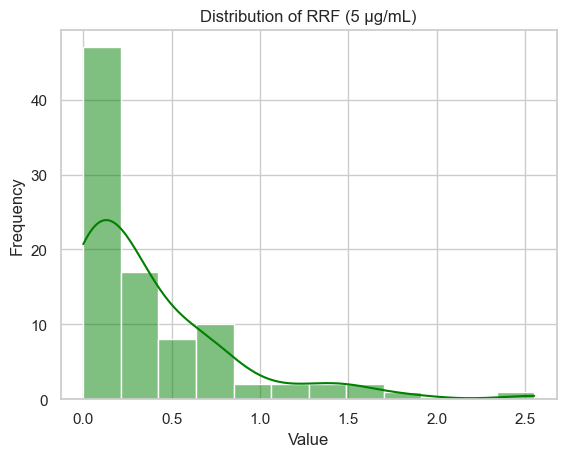

In [10]:
sns.histplot(df_final['5 µg/mL'], kde=True, color='green')
plt.title('Distribution of RRF (5 µg/mL)')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.show()

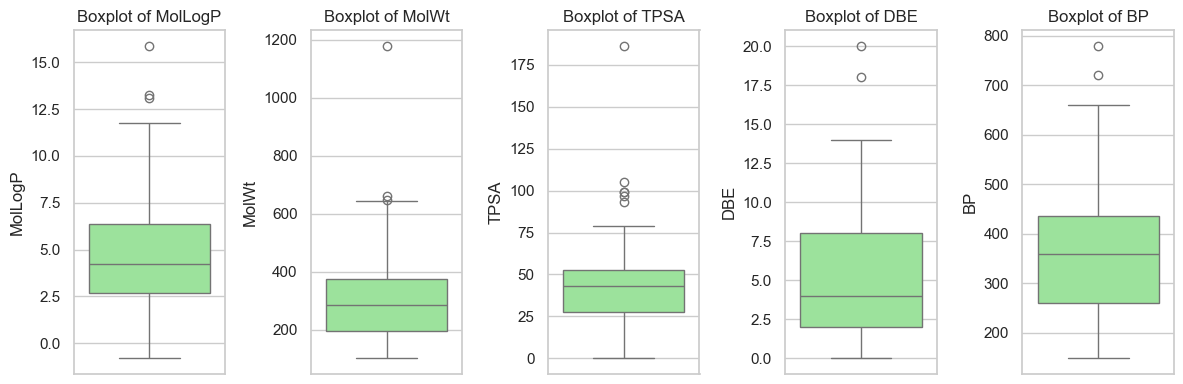

In [11]:
key_desc = ['MolLogP', 'MolWt', 'TPSA', 'DBE', 'BP']

plt.figure(figsize=(12, 4))
for i, col in enumerate(key_desc):
    plt.subplot(1, 5, i+1)
    sns.boxplot(y=df_final[col], color='lightgreen')
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

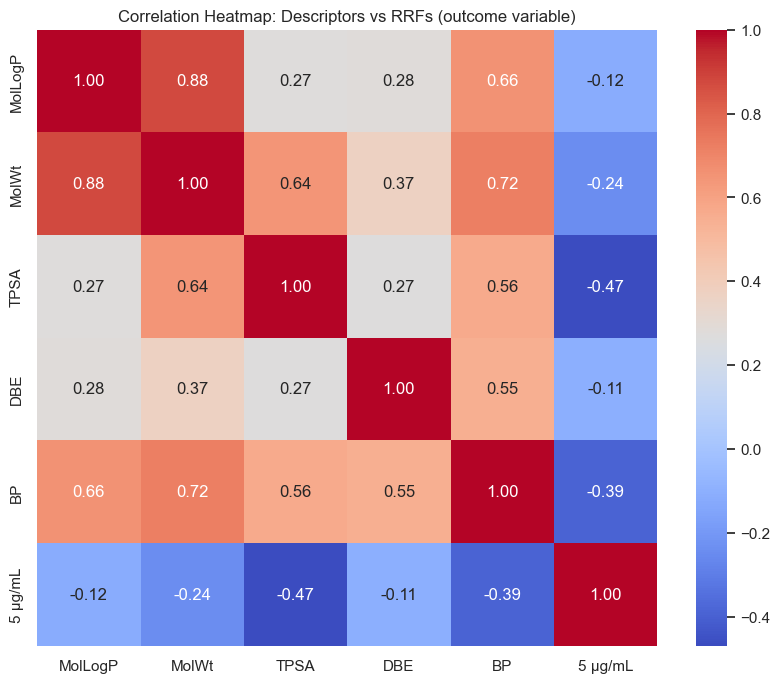

In [12]:
corr_matrix = df_final[key_desc + ['5 µg/mL']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap: Descriptors vs RRFs (outcome variable)')
plt.show()

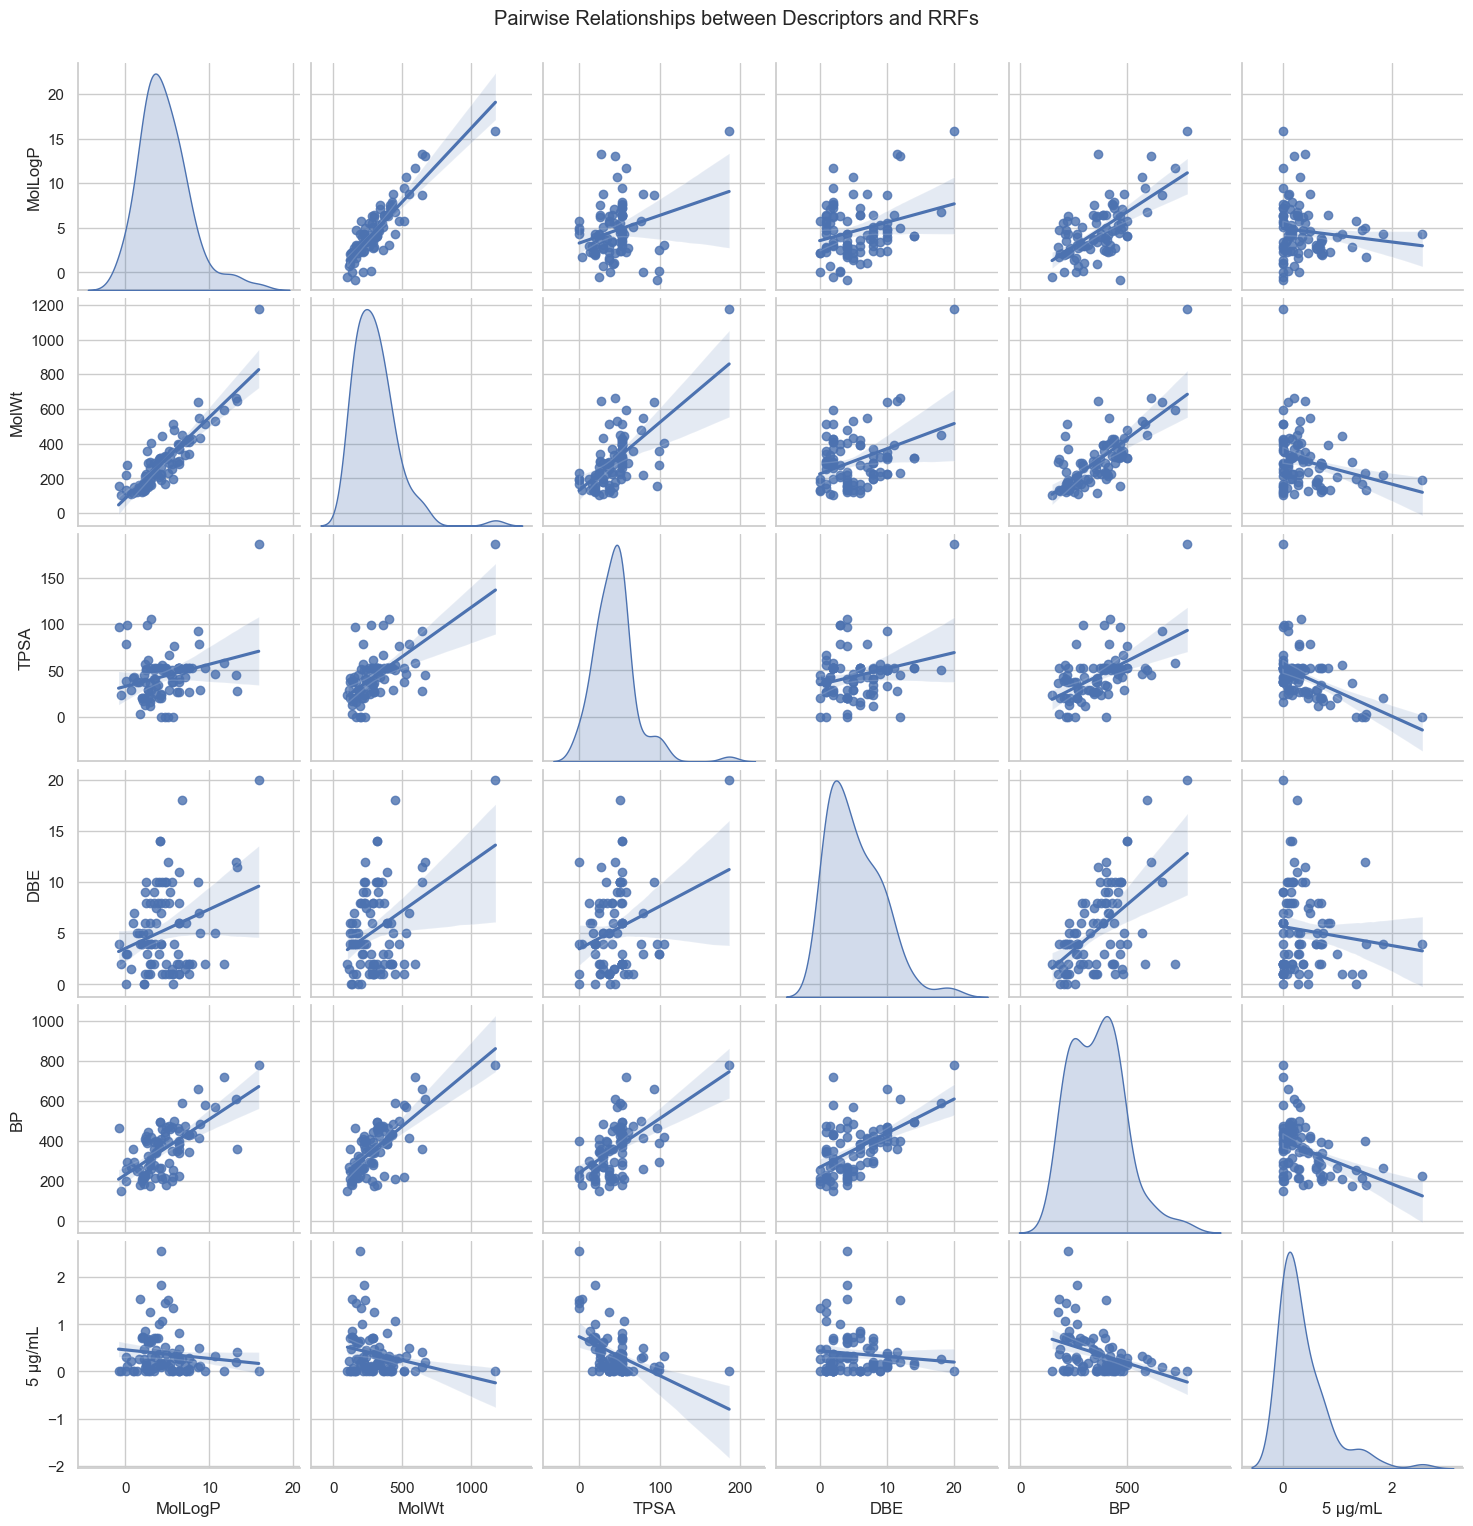

In [13]:
sns.pairplot(df_final, vars=['MolLogP', 'MolWt', 'TPSA', 'DBE', 'BP', '5 µg/mL'], kind='reg', diag_kind='kde')
plt.suptitle('Pairwise Relationships between Descriptors and RRFs', y=1.02)
plt.show()

### Multiple imputation for missing values

I selected relevant descriptors in addition to the ones provided by the CLAP list. Another version exist with all predictors.

In [14]:
missing_data = df_final.isnull().sum()
missing_data = missing_data[missing_data > 0].sort_values(ascending=False)

print(missing_data)


pKa                 27
Refractive Index     3
BP                   1
dtype: int64


Missing values exist for `pKA` (27),  `Refractive Index`(3), `BP`(1).
Values for RI and BP will be imputed using Multiple Imputation. pKA will not be used in the models.

In [15]:
X = df_final.drop(['5 µg/mL', 'IUPAC name', 'CAS #', 'Empirical Formula', '10 µg/mL', '20 µg/mL', 'Code', 'pKa', 'SMILES'] , axis=1) # Features without the 5 µg/mL RRF
y = df_final['5 µg/mL'] # outcome

# Multiple Imputation using IterativeImputer
imputer = IterativeImputer(max_iter=10, random_state=42)
scaler = StandardScaler()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

# Impute and Scale (for Elastic Net and SVM)
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

# Keep as DataFrames for feature selection reference
feature_names = X.columns
X_train_df = pd.DataFrame(X_train_scaled, columns=feature_names)
X_test_df = pd.DataFrame(X_test_scaled, columns=feature_names)


X_train_sel = X_train_df
X_test_sel = X_test_df

temp_rf = RandomForestRegressor(n_estimators=100, random_state=42)
temp_rf.fit(X_train_df, y_train)
importances = pd.Series(temp_rf.feature_importances_, index=feature_names)
top_20_features = importances.sort_values(ascending=False).head(20).index

X_train_top = X_train_df[top_20_features]
X_test_top = X_test_df[top_20_features]

## 5. Model Selection

As we have a continuous outcome: we will fit three models : \\
Elastic regression (parametric) \\
Random Forests (non-parametric)  \\
Support Vector Machines (non-parametric) \\


## 6. Model training

### ELastic Net Regression

In [16]:
enet = ElasticNet(random_state=42)
enet.fit(X_train_sel, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the penalty terms. Defaults to 1.0.See the notes for the exact mathematical meaning of thisparameter. ``alpha = 0`` is equivalent to an ordinary least square,solved by the :class:`LinearRegression` object. For numericalreasons, using ``alpha = 0`` with the ``Lasso`` object is not advised.Given this, you should use the :class:`LinearRegression` object.",1.0
,"l1_ratio l1_ratio: float, default=0.5The ElasticNet mixing parameter, with ``0 <= l1_ratio <= 1``. For``l1_ratio = 0`` the penalty is an L2 penalty. ``For l1_ratio = 1`` itis an L1 penalty. For ``0 < l1_ratio < 1``, the penalty is acombination of L1 and L2.",0.5
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If ``False``, thedata is assumed to be already centered.",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.Check :ref:`an example on how to use a precomputed Gram Matrix in ElasticNet`for details.",False
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary `.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


### Random Forest

In [17]:
RF_model = RandomForestRegressor(n_estimators=100,
                   random_state=42, n_jobs=-1)
RF_model.fit(X_train_top, y_train) 

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

## Gradient Boosting (LGBM)

In [18]:
LGBM_model = LGBMRegressor()
LGBM_model.fit(X_train_top, y_train)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000222 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 378
[LightGBM] [Info] Number of data points in the train set: 64, number of used features: 20
[LightGBM] [Info] Start training from score 0.399734
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, bes

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


### Support Vector Machine

In [19]:
svm_model = SVR(kernel='rbf')
svm_model.fit(X_train_sel, y_train)


,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [20]:
models = {
    'ElasticNet': enet,
    'Random Forest': RF_model,
    'Gradient Boosting (LGBM)': LGBM_model,
    'SVM': svm_model
}

## 7. Model Evaluation

In [21]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)

def evaluate_model_cv(model, X, y, model_name="Model"):
    cv_predictions = cross_val_predict(model, X, y, cv=kf, n_jobs=-1)
    
    cv_r2 = r2_score(y, cv_predictions)
    cv_mae = mean_absolute_error(y, cv_predictions)
    cv_rmse = np.sqrt(mean_squared_error(y, cv_predictions))
    
    print(f"--- {model_name} (k-Fold CV) ---")
    print(f"R²:   {cv_r2:.4f}")
    print(f"MAE:  {cv_mae:.4f}")
    print(f"RMSE: {cv_rmse:.4f}\n")
    
    return cv_predictions

cv_results = {}
for name, model in models.items():
    if name in ['Elastic Net', 'SVM']:
        cv_results[name] = evaluate_model_cv(model, X_train_sel, y_train, name)
    else:
        cv_results[name] = evaluate_model_cv(model, X_train_top, y_train, name)

--- ElasticNet (k-Fold CV) ---
R²:   -0.0139
MAE:  0.3340
RMSE: 0.4691

--- Random Forest (k-Fold CV) ---
R²:   0.4043
MAE:  0.2454
RMSE: 0.3596

--- Gradient Boosting (LGBM) (k-Fold CV) ---
R²:   0.2848
MAE:  0.2668
RMSE: 0.3940

--- SVM (k-Fold CV) ---
R²:   0.4405
MAE:  0.2409
RMSE: 0.3485



## 8. Model optimisation for Random Forest and SVM

Elastic Regression was already optimised during the feature engineering. Therefore, we focus the hyperparameter tuning for RF and SVM.

The strategy is to use a Bayesian optimization (Optuna), to ensure that all parameters will optimise the objective function (maximizing R²)

In [22]:
def objective_svm(trial):
    c = trial.suggest_float('C', 1e-3, 1e2, log=True)
    epsilon = trial.suggest_float('epsilon', 1e-3, 0.5, log=True)
    gamma = trial.suggest_categorical('gamma', ['scale', 'auto'])
    
    model = SVR(C=c, epsilon=epsilon, gamma=gamma)
    
    score = cross_val_score(model, X_train_sel, y_train, cv=5, scoring='r2').mean()
    return score

study_svm = optuna.create_study(direction='maximize')
study_svm.optimize(objective_svm, n_trials=30)

def objective_rf(trial):
    n_estimators = trial.suggest_int('n_estimators', 50, 1000)
    max_depth = trial.suggest_int('max_depth', 2, 32, log=True)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 20)
    
    model = RandomForestRegressor(
        n_estimators=n_estimators, 
        max_depth=max_depth, 
        min_samples_split=min_samples_split,
        random_state=42
    )
    
    score = cross_val_score(model, X_train_top, y_train, cv=5, scoring='r2').mean()
    return score

study_rf = optuna.create_study(direction='maximize')
study_rf.optimize(objective_rf, n_trials=30)

def objective_lgbm(trial):
    param = {
        'objective': 'regression',
        'metric': 'rmse',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'lambda_l1': trial.suggest_float('lambda_l1', 1e-8, 10.0, log=True),
        'lambda_l2': trial.suggest_float('lambda_l2', 1e-8, 10.0, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 2, 256),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.4, 1.0),
        'bagging_fraction': trial.suggest_float('bagging_fraction', 0.4, 1.0),
        'bagging_freq': trial.suggest_int('bagging_freq', 1, 7),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
    }

    model = LGBMRegressor(**param)
    score = cross_val_score(model, X_train_top, y_train, cv=5, scoring='r2').mean()
    return score

study_lgbm = optuna.create_study(direction='maximize')
study_lgbm.optimize(objective_lgbm, n_trials=50)

[I 2026-03-20 15:41:40,500] A new study created in memory with name: no-name-c2c7c44b-11ba-4b7a-b8d5-635d1ce69871
[I 2026-03-20 15:41:40,546] Trial 0 finished with value: 0.3968014498357191 and parameters: {'C': 59.69624522612223, 'epsilon': 0.005469946331782728, 'gamma': 'scale'}. Best is trial 0 with value: 0.3968014498357191.
[I 2026-03-20 15:41:40,574] Trial 1 finished with value: -0.2143209905554025 and parameters: {'C': 0.08880960750594598, 'epsilon': 0.4802237041547089, 'gamma': 'scale'}. Best is trial 0 with value: 0.3968014498357191.
[I 2026-03-20 15:41:40,601] Trial 2 finished with value: -0.1421733932523382 and parameters: {'C': 0.0010441739262604627, 'epsilon': 0.037022595556272436, 'gamma': 'auto'}. Best is trial 0 with value: 0.3968014498357191.
[I 2026-03-20 15:41:40,627] Trial 3 finished with value: 0.08938244845783223 and parameters: {'C': 0.1920900352383058, 'epsilon': 0.25152405285018403, 'gamma': 'auto'}. Best is trial 0 with value: 0.3968014498357191.
[I 2026-03-20

In [23]:
optuna.visualization.plot_optimization_history(study_svm)

In [24]:
optuna.visualization.plot_param_importances(study_svm)


In [25]:
optuna.visualization.plot_optimization_history(study_rf)

In [26]:
optuna.visualization.plot_param_importances(study_rf)

In [27]:
optuna.visualization.plot_optimization_history(study_lgbm)

In [28]:
def plot_model_performance(y_true, y_pred, model_name):
    """
    Generates Predicted vs Actual and Residuals plots
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Plot 1: Predicted vs Actual
    
    axes[0].scatter(y_true, y_pred, alpha=0.6, color='blue', edgecolor='k')
    
    # Perfect prediction line
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2)
    
    axes[0].set_title(f'{model_name}: Predicted vs Actual')
    axes[0].set_xlabel('Actual RRF')
    axes[0].set_ylabel('Predicted RRF')
    axes[0].grid(True)

    # Plot 2: Residuals
    residuals = y_true - y_pred
    axes[1].scatter(y_pred, residuals, alpha=0.6, color='purple', edgecolor='k')
    axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
    
    axes[1].set_title(f'{model_name}: Residual Plot')
    axes[1].set_xlabel('Predicted RRF')
    axes[1].set_ylabel('Residuals (Actual - Predicted)')
    axes[1].grid(True)
    
    plt.tight_layout()
    plt.show()

### Model evaluation on the Optimized Models

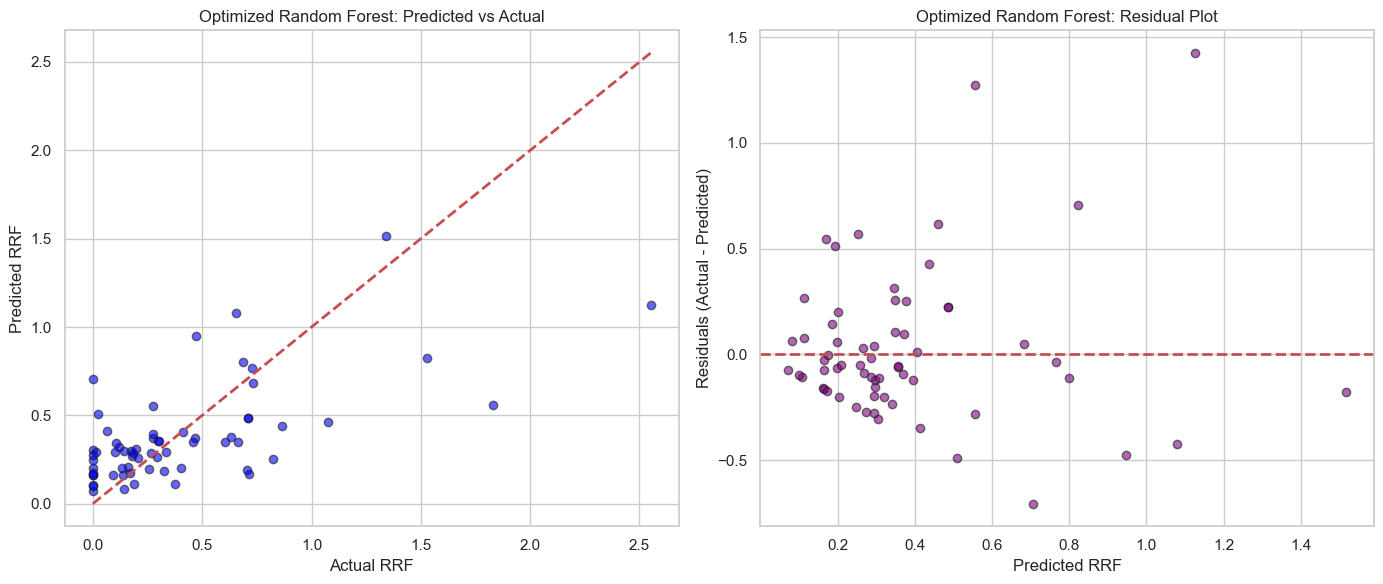

--- Final Optimized RF Metrics ---
CV R²: 0.4104
CV RMSE: 0.3577
--- PERFORMANCE ON HOLD-OUT TEST SET ---
Test R²:   0.6655
Test RMSE: 0.2578


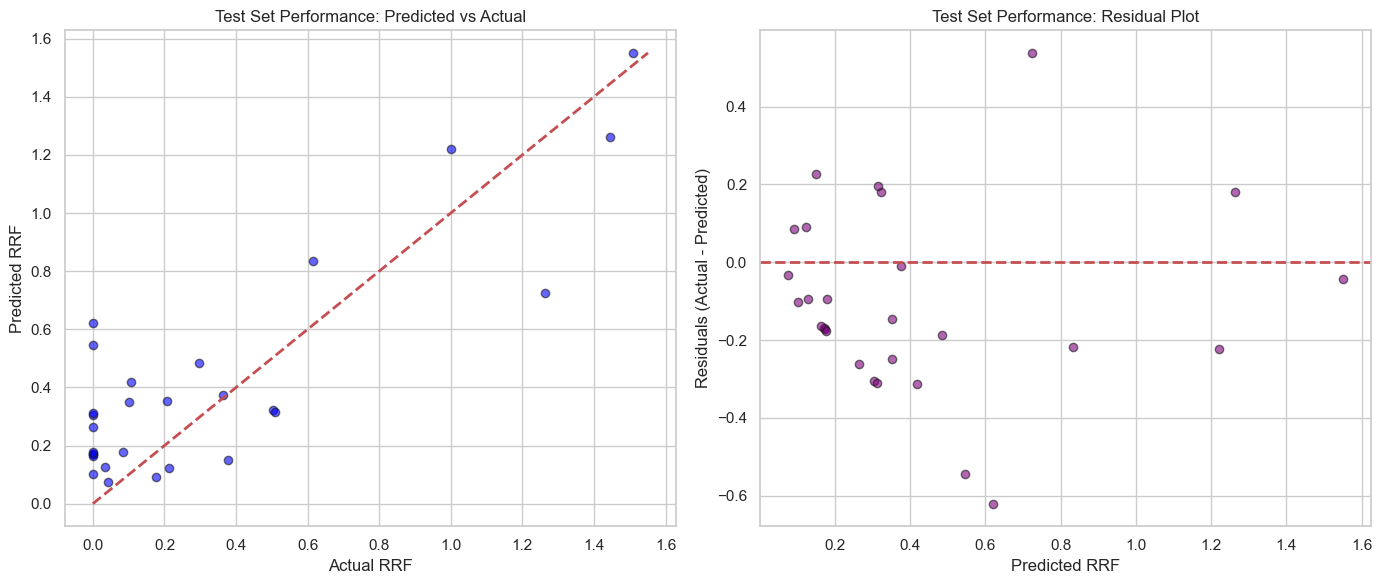

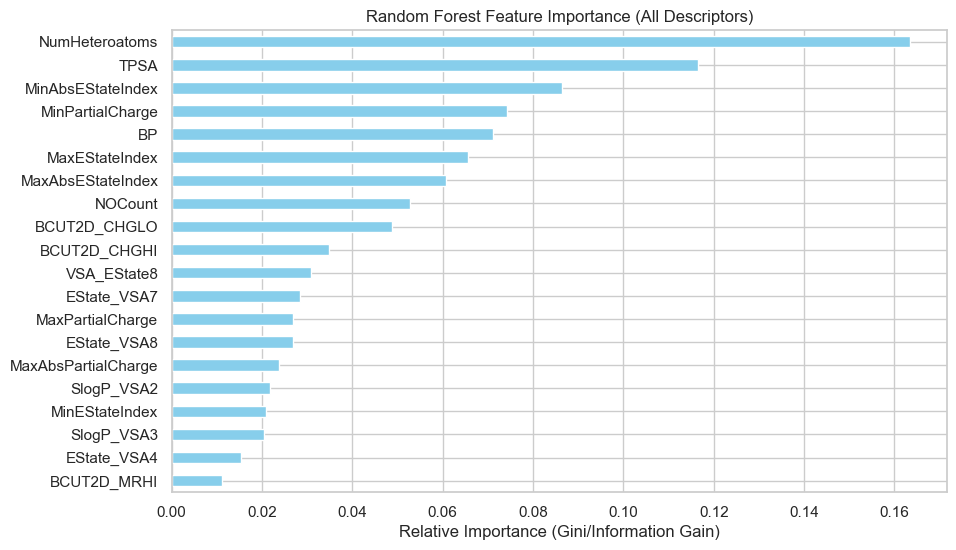

['NumHeteroatoms', 'TPSA', 'MinAbsEStateIndex', 'MinPartialCharge', 'BP', 'MaxEStateIndex', 'MaxAbsEStateIndex', 'NOCount', 'BCUT2D_CHGLO', 'BCUT2D_CHGHI', 'VSA_EState8', 'EState_VSA7', 'MaxPartialCharge', 'EState_VSA8', 'MaxAbsPartialCharge', 'SlogP_VSA2', 'MinEStateIndex', 'SlogP_VSA3', 'EState_VSA4', 'BCUT2D_MRHI']


In [29]:
best_rf = RandomForestRegressor(**study_rf.best_params, random_state=42, n_jobs=-1)

best_rf.fit(X_train_top, y_train)

cv_preds_final = cross_val_predict(best_rf, X_train_top, y_train, cv=kf, n_jobs=-1)

plot_model_performance(y_train, cv_preds_final, "Optimized Random Forest")

print("--- Final Optimized RF Metrics ---")
print(f"CV R²: {r2_score(y_train, cv_preds_final):.4f}")
print(f"CV RMSE: {np.sqrt(mean_squared_error(y_train, cv_preds_final)):.4f}")

test_predictions = best_rf.predict(X_test_top)

print("--- PERFORMANCE ON HOLD-OUT TEST SET ---")
print(f"Test R²:   {r2_score(y_test, test_predictions):.4f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, test_predictions)):.4f}")

# Optional: Visualize Test Set performance
plot_model_performance(y_test, test_predictions, "Test Set Performance")

importances = best_rf.feature_importances_
feat_importances = pd.Series(importances, index=X_train_top.columns)

plt.figure(figsize=(10, 6))
feat_importances.nlargest(20).sort_values(ascending=True).plot(kind='barh', color='skyblue')
plt.title('Random Forest Feature Importance (All Descriptors)')
plt.xlabel('Relative Importance (Gini/Information Gain)')
plt.show()

selected_features = feat_importances.nlargest(20).index.tolist()
print(selected_features)

# Best LGBM

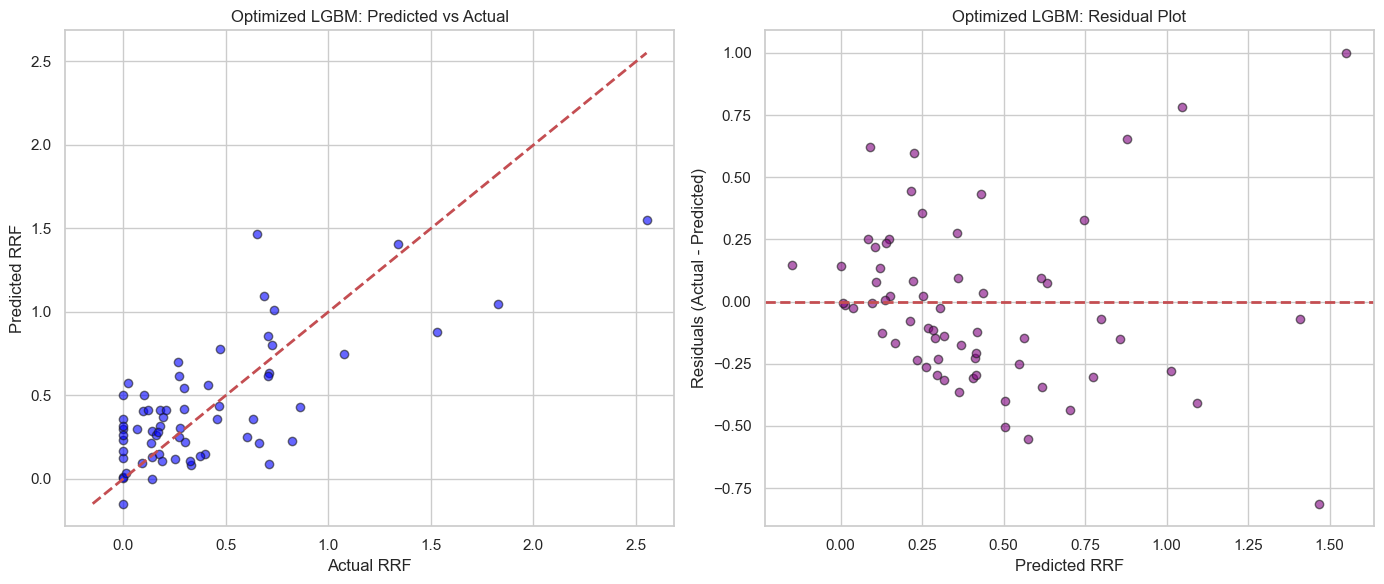

--- Final Optimized LGBM Metrics ---
CV R²: 0.5047
CV RMSE: 0.3279
--- PERFORMANCE ON HOLD-OUT TEST SET ---
Test R²:   0.6195
Test RMSE: 0.2749


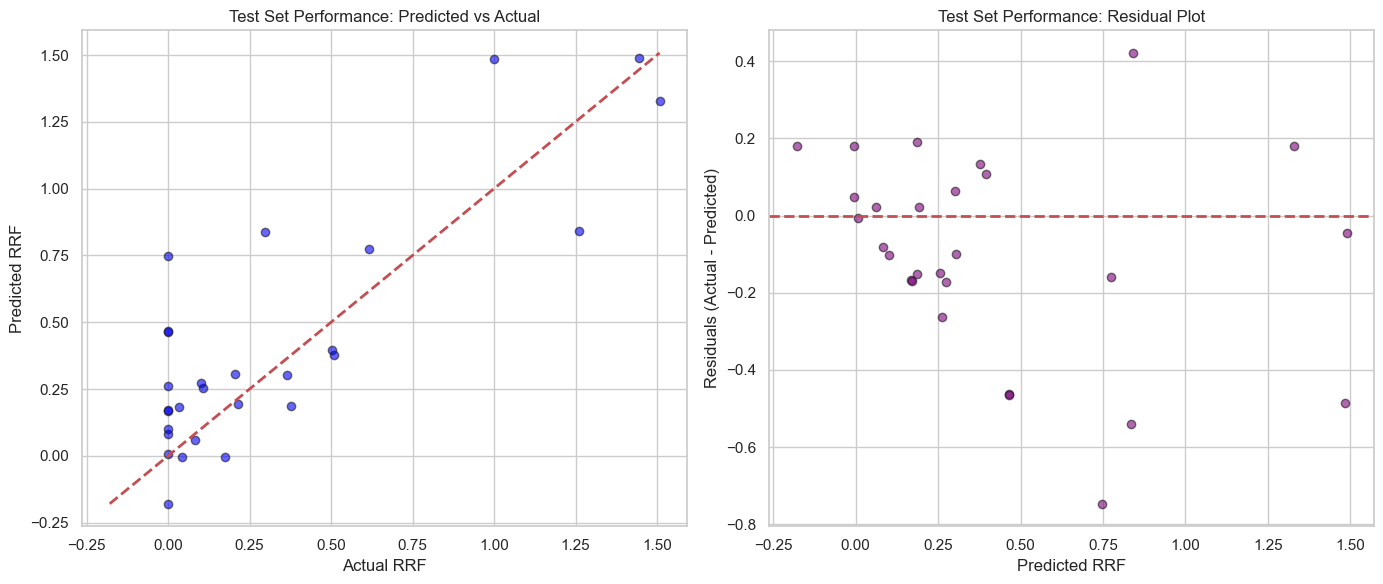

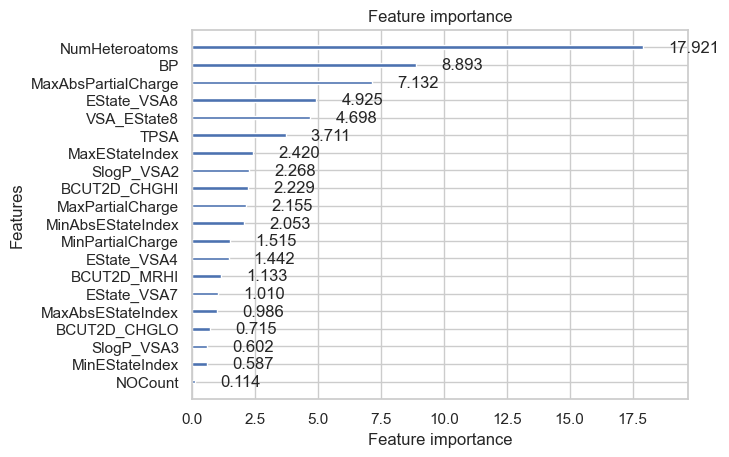

In [30]:
import lightgbm as lgb

best_LGBM = LGBMRegressor(**study_lgbm.best_params, random_state=42, n_jobs=-1)

best_LGBM.fit(X_train_top, y_train)

cv_preds_final = cross_val_predict(best_LGBM, X_train_top, y_train, cv=kf, n_jobs=-1)

plot_model_performance(y_train, cv_preds_final, "Optimized LGBM")

print("--- Final Optimized LGBM Metrics ---")
print(f"CV R²: {r2_score(y_train, cv_preds_final):.4f}")
print(f"CV RMSE: {np.sqrt(mean_squared_error(y_train, cv_preds_final)):.4f}")

test_predictions = best_LGBM.predict(X_test_top)

print("--- PERFORMANCE ON HOLD-OUT TEST SET ---")
print(f"Test R²:   {r2_score(y_test, test_predictions):.4f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, test_predictions)):.4f}")

# Optional: Visualize Test Set performance
plot_model_performance(y_test, test_predictions, "Test Set Performance")

lgb.plot_importance(best_LGBM, max_num_features=20, importance_type='gain')
plt.show()

importances = best_LGBM.booster_.feature_importance(importance_type='gain')
feature_names = X_train_top.columns
lgbm_feat_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values(by='importance', ascending=False)



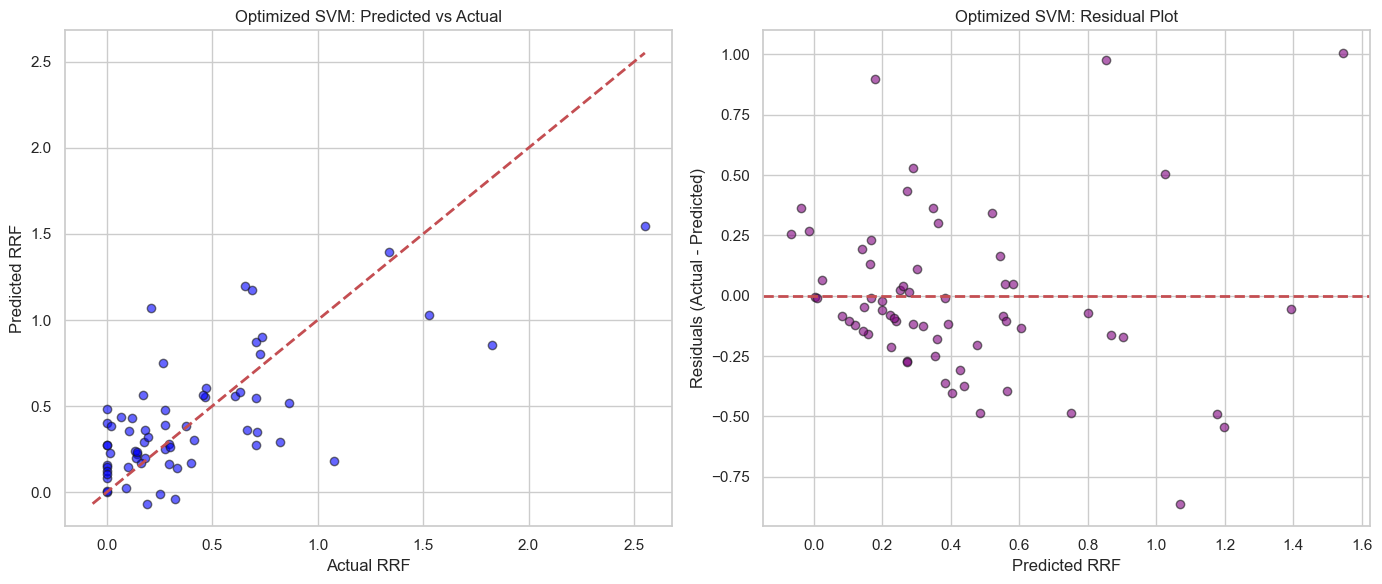

--- Final Optimized RF Metrics ---
CV R²: 0.4766
CV RMSE: 0.3370
--- PERFORMANCE ON HOLD-OUT TEST SET ---
Test R²:   0.6441
Test RMSE: 0.2659


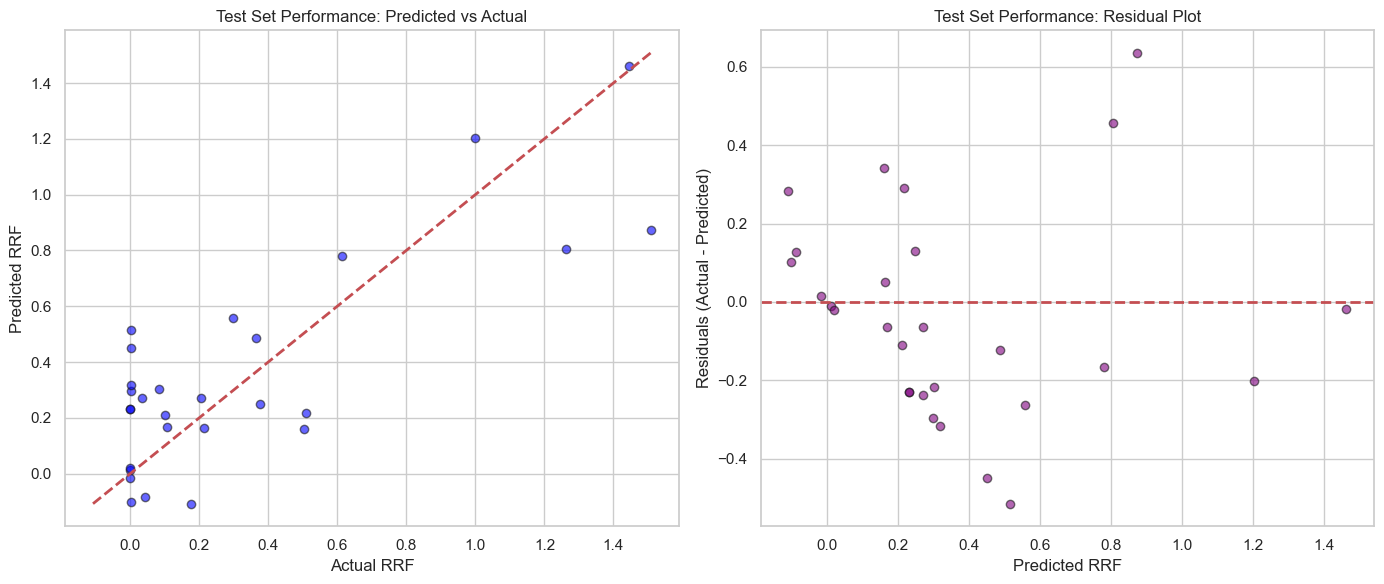

In [31]:
best_svm = SVR(**study_svm.best_params)
               
best_svm.fit(X_train_sel, y_train)

cv_preds_final = cross_val_predict(best_svm, X_train_sel, y_train, cv=kf, n_jobs=-1)

plot_model_performance(y_train, cv_preds_final, "Optimized SVM")

print("--- Final Optimized RF Metrics ---")
print(f"CV R²: {r2_score(y_train, cv_preds_final):.4f}")
print(f"CV RMSE: {np.sqrt(mean_squared_error(y_train, cv_preds_final)):.4f}")

test_predictions = best_svm.predict(X_test_sel)

print("--- PERFORMANCE ON HOLD-OUT TEST SET ---")
print(f"Test R²:   {r2_score(y_test, test_predictions):.4f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, test_predictions)):.4f}")

plot_model_performance(y_test, test_predictions, "Test Set Performance")

## Save the model & the final dataset 

In [32]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler

importances = pd.Series(best_rf.feature_importances_, index=feature_names)
top_20_features_list = list(top_20_features) # Ensure it's a list

# Build pipeline to handle Imputation and Scaling dynamically
final_pipeline = Pipeline([
    ('imputer', IterativeImputer(max_iter=10, random_state=42)),
    ('scaler', StandardScaler()),
    ('rf', RandomForestRegressor(**study_rf.best_params, random_state=42, n_jobs=-1))
])

# Fit on unscaled, raw top 20 features
X_train_raw_top = X_train[top_20_features_list]
final_pipeline.fit(X_train_raw_top, y_train)

joblib.dump(final_pipeline, 'rf_rrf_model_final_20.joblib')
joblib.dump(top_20_features_list, 'features_20.joblib')

df_final.to_csv("final_model_data.csv", index=False)


In [34]:
import sklearn, numpy, pandas, joblib
with open("model_environment.txt", "w") as f:
    f.write(f"scikit-learn=={sklearn.__version__}\n")
    f.write(f"numpy=={numpy.__version__}\n")
    f.write(f"pandas=={pandas.__version__}\n")
    f.write(f"joblib=={joblib.__version__}\n")